# DSO 607 · Homework 3 · Problem 1
## Lasso and SCAD model selection under collinearity

**Parts (a), (b), and (c)** · Reproducible Monte Carlo experiment · Fall 2026

This notebook implements Problem 1 of the supplied `homework3.pdf`. It generates **100 independent data sets at each of four correlations**, fits both complete decreasing paths, and reports support recovery, Monte Carlo uncertainty, finite discrepancy distributions, and optimization diagnostics. The saved notebook includes executed outputs.

**Run:** Use a Python 3 kernel and choose **Restart Kernel and Run All**. The notebook is self-contained; the PDF and external data files are not needed. Required packages are NumPy, SciPy, pandas, Matplotlib, scikit-learn, and Numba. If needed, run the commented installation command below and restart the kernel. Numba compiles the coordinate-descent routines on their first call. Full execution can take several minutes, depending on hardware.

**Scope:** This is the Problem 1 notebook, not the complete two-problem homework submission. Paths are evaluated on the required finite grid, rather than over every real-valued tuning parameter. SCAD uses a specified stationary-solution path; global optimality is not asserted.

In [60]:
# Run only if a package is missing, then restart the kernel:
%pip install numpy scipy pandas matplotlib scikit-learn numba

import sys
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import numba
from numba import njit
from scipy.optimize import minimize_scalar
from scipy.stats import norm
from sklearn.linear_model import lasso_path
from IPython.display import display, Markdown

plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 160, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18, 'axes.axisbelow': True,
})
COLORS = {'Lasso': '#285B9A', 'SCAD': '#C75D30'}
pd.set_option('display.max_columns', 16)
pd.set_option('display.width', 160)

versions = {'Python': platform.python_version(), 'NumPy': np.__version__,
            'SciPy': scipy.__version__, 'pandas': pd.__version__,
            'Matplotlib': matplotlib.__version__, 'scikit-learn': sklearn.__version__,
            'Numba': numba.__version__}
display(pd.Series(versions, name='Version').to_frame())

64330.65s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


You should consider upgrading via the '/Users/wchae/Courseworks/26 Fall/DSO607/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


,Version
Python,3.9.6
NumPy,2.0.2
SciPy,1.13.1
pandas,2.3.3
Matplotlib,3.9.4
scikit-learn,1.6.1
Numba,0.60.0


## Shared setup: design, objectives, and path definition

Generate the **raw** design and response first:
$$
X^{\rm raw}_{ij}=\sqrt r\,Z_{i0}+\sqrt{1-r}\,Z_{ij},\qquad
 y^{\rm raw}=X^{\rm raw}\beta^0+\epsilon,
$$
with $n=100$, $p=1000$, $\sigma=0.3$,
$\beta^0=(1,-0.5,0.7,-1.2,-0.9,0.3,0.55,0,\ldots,0)^T$, and $S_0=\{1,\ldots,7\}$.
Then center $y$ and standardize each centered column of $X$ to norm $\sqrt n$.
Generating the response before standardization preserves the design specified in the assignment. If the raw-column scale is $s_j$, the corresponding true standardized coefficient is $s_j\beta_j^0$; its support is unchanged.

Both solvers minimize
$$
    Q(\beta;\lambda)=\frac{\|y-X\beta\|_2^2}{2n} + \sum_j p_\lambda(|\beta_j|).
$$
For Lasso, $p_\lambda(t)=\lambda t$. For SCAD with $a=3.7$, integrating the supplied derivative with $p_{\lambda,a}(0)=0$ gives
$$
p_{\lambda,a}(t)=
\begin{cases}
\lambda t,&0\le t\le\lambda,\\
\dfrac{-t^2+2a\lambda t-\lambda^2}{2(a-1)},&\lambda<t\le a\lambda,\\
\dfrac{(a+1)\lambda^2}{2},&t>a\lambda.
\end{cases}
$$

In [61]:
MASTER_SEED = 20261017
N, P, SIGMA = 100, 1000, 0.3
BETA0 = np.r_[np.array([1., -0.5, 0.7, -1.2, -0.9, 0.3, 0.55]), np.zeros(P-7)]
S0 = np.arange(7)  # Python indices 0,...,6 correspond to assignment variables 1,...,7.
S0_SIZE = len(S0)
R_GRID = (0., 0.25, 0.50, 0.75)
N_REP = 100
N_LAMBDA = 100
MIN_RATIO = 0.02
A_SCAD = 3.7
SUPPORT_TOL = 1e-6
SOLVER = dict(a=A_SCAD, cd_tol=1e-8, kkt_tol=1e-7, max_sweeps=50000)
METHODS = ('Lasso', 'SCAD')
assert N_REP >= 100 and N_LAMBDA >= 60

# Each (r, replication) has its own deterministic random stream.
# Both methods use exactly the same data and lambda grid within a replication.
# Streams are independent across r, and do not depend on the order of execution.

In [62]:
def simulate(r, replication=0, seed=20261017, n=100, p=1000):
    rng = np.random.default_rng(np.random.SeedSequence([seed,int(round(100*r)),replication]))
    beta0 = np.zeros(p)
    beta0[:7] = [1.,-.5,.7,-1.2,-.9,.3,.55]
    common = rng.standard_normal((n,1))
    raw = np.sqrt(r)*common + np.sqrt(1-r)*rng.standard_normal((n,p))
    y_raw = np.einsum("ij,j->i", raw, beta0) + .3*rng.standard_normal(n)
    means = raw.mean(axis=0)
    centered = raw-means
    scales = np.sqrt(np.mean(centered**2,axis=0))
    X = np.asfortranarray(centered/scales)
    return X, y_raw-y_raw.mean(), {'beta0':beta0,'scales':scales,'means':means,'y_mean':y_raw.mean()}


def lambda_grid(X, y, n_lambda=N_LAMBDA):
    lambda_max = np.max(np.abs(np.einsum('ij,i->j', X, y)))/len(y)
    return np.geomspace(lambda_max, MIN_RATIO*lambda_max, n_lambda)

# One design check; independent of the 400 experimental data sets.
X_check, y_check, metadata_check = simulate(0.5, replication=9999, seed=MASTER_SEED)
assert np.max(np.abs(X_check.mean(axis=0))) < 1e-12
assert np.allclose(np.sum(X_check**2, axis=0), N, atol=1e-10)
assert abs(y_check.mean()) < 1e-12
assert np.isfinite(X_check).all() and np.isfinite(y_check).all()
assert np.array_equal(metadata_check['beta0'], BETA0)
print('Design checks passed: centered response; centered predictors with squared norm n.')

Design checks passed: centered response; centered predictors with squared norm n.


### Solver specification and convergence

For standardized columns, let $z_j=\beta_j+X_j^T(y-X\beta)/n$.
The Lasso update is $S(z_j,\lambda)=\operatorname{sign}(z_j)(|z_j|-\lambda)_+$.
The SCAD update is the **exact one-coordinate minimizer**:
$$
T(z,\lambda)=\begin{cases}
S(z,\lambda),&|z|\le2\lambda,\\
\dfrac{(a-1)z-\operatorname{sign}(z)a\lambda}{a-2},&2\lambda<|z|\le a\lambda,\\
z,&|z|>a\lambda.
\end{cases}
$$
Each coordinate subproblem is strictly convex when $a>2$, although the joint SCAD objective can be nonconvex. See [Breheny and Huang (2011)](https://arxiv.org/abs/1104.2748), §2.

- **Grid:** 100 log-spaced values from $\lambda_{\max}=\|X^Ty/n\|_\infty$ through $0.02\lambda_{\max}$, including both endpoints. No early stopping of the path.
- **Initialization:** the zero vector at the largest $\lambda$, separately for each method. Each subsequent fit starts at that method's preceding solution. Coordinate order is always $1,\ldots,p$.
- **Sweeps:** a full sweep, followed by sweeps over its active coordinates; a full sweep is required again before convergence. Inactive coordinates are revisited, and no screening rule permanently removes variables.
- **Stopping:** after a full sweep, the largest coefficient change must be at most $10^{-8}(1+\|\beta\|_\infty)$, and the maximum stationarity/KKT violation must be at most $10^{-7}\max(1,\lambda)$. The residual is recomputed before this check.
- **KKT check:** if $\beta_j=0$, $(|X_j^Tr/n|-\lambda)_+$ must be small; otherwise $|X_j^Tr/n-p'_{\lambda}(|\beta_j|)\operatorname{sign}(\beta_j)|$ must be small. Values of magnitude at most $10^{-12}$ count as zero only in this numerical KKT check.
- **Limits and support:** maximum 50,000 sweeps per tuning value; $|\widehat\beta_j|>10^{-6}$ defines the reported support. A failed fit raises an error; it is never silently included as a result.

The implementation tracks objective increases **within a fixed tuning value**. Objectives at different tuning values need not be comparable. For SCAD, stationarity does not certify a global minimizer or eliminate dependence on initialization.

In [63]:
@njit
def threshold(z, lam, method, a=3.7):
    az = abs(z)
    if method == 0 or az <= 2.0 * lam:
        v = max(az - lam, 0.0)
    elif az <= a * lam:
        v = ((a - 1.0) * az - a * lam) / (a - 2.0)
    else:
        v = az
    return np.copysign(v, z)

@njit
def penalty_value(t, lam, method, a=3.7):
    if method == 0 or t <= lam:
        return lam * t
    if t <= a * lam:
        return (-t*t + 2.0*a*lam*t - lam*lam)/(2.0*(a-1.0))
    return (a+1.0)*lam*lam/2.0

@njit
def objective_residual(residual, beta, lam, method, a):
    value = np.dot(residual, residual)/(2.0*len(residual))
    for j in range(len(beta)):
        value += penalty_value(abs(beta[j]), lam, method, a)
    return value

@njit
def kkt_residual(X, residual, beta, lam, method, a):
    n, p = X.shape
    violation = 0.0
    for j in range(p):
        corr = np.dot(X[:, j], residual)/n
        t = abs(beta[j])
        if t <= 1e-12:
            v = max(abs(corr)-lam, 0.0)
        else:
            deriv = lam
            if method == 1 and t > lam:
                deriv = max(a*lam-t, 0.0)/(a-1.0)
            v = abs(corr-np.copysign(deriv, beta[j]))
        violation = max(violation, v)
    return violation

@njit
def solve_one(X, y, lam, method, initial, a=3.7, cd_tol=1e-8,
              kkt_tol=1e-7, max_sweeps=50000):
    # Columns must be centered with squared norm n. method=0: Lasso; method=1: SCAD.
    n, p = X.shape
    beta = initial.copy()
    residual = y.copy()
    for j in range(p):
        if beta[j] != 0.0:
            residual -= X[:, j]*beta[j]
    previous_obj = objective_residual(residual, beta, lam, method, a)
    start_obj = previous_obj
    max_increase = 0.0
    full_sweep = True
    violation = np.inf
    for sweep in range(1, max_sweeps+1):
        largest_change = 0.0
        for j in range(p):
            if not full_sweep and beta[j] == 0.0:
                continue
            old = beta[j]
            z = old + np.dot(X[:, j], residual)/n
            new = threshold(z, lam, method, a)
            delta = new-old
            if delta != 0.0:
                beta[j] = new
                residual -= X[:, j]*delta
                largest_change = max(largest_change, abs(delta))
        current_obj = objective_residual(residual, beta, lam, method, a)
        max_increase = max(max_increase, current_obj-previous_obj)
        previous_obj = current_obj
        if largest_change <= cd_tol*(1.0+np.max(np.abs(beta))):
            if full_sweep:
                # Recompute residual to prevent accumulated roundoff from certifying convergence.
                residual = y.copy()
                for j in range(p):
                    if beta[j] != 0.0:
                        residual -= X[:, j]*beta[j]
                violation = kkt_residual(X, residual, beta, lam, method, a)
                if violation <= kkt_tol*max(1.0, lam):
                    return beta, sweep, violation, True, max_increase, start_obj, current_obj
            full_sweep = True
        else:
            full_sweep = False
    violation = kkt_residual(X, residual, beta, lam, method, a)
    return beta, max_sweeps, violation, False, max_increase, start_obj, previous_obj

@njit
def solve_path_core(X, y, lambdas, method, a=3.7, cd_tol=1e-8,
                    kkt_tol=1e-7, max_sweeps=50000):
    p = X.shape[1]
    length = len(lambdas)
    coefs = np.zeros((p, length))
    sweeps = np.zeros(length, dtype=np.int64)
    violations = np.zeros(length)
    converged = np.zeros(length, dtype=np.bool_)
    increases = np.zeros(length)
    beta = np.zeros(p)
    for k in range(length):
        result = solve_one(X, y, lambdas[k], method, beta, a, cd_tol, kkt_tol, max_sweeps)
        beta, sweeps[k], violations[k], converged[k], increases[k], _, _ = result
        coefs[:, k] = beta
    return coefs, sweeps, violations, converged, increases

def fit_path(X, y, lambdas, method, **kwargs):
    X = np.asfortranarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    lambdas = np.asarray(lambdas, dtype=np.float64)
    if np.any(lambdas <= 0) or np.any(np.diff(lambdas) >= 0):
        raise ValueError('Supply strictly positive, strictly decreasing lambdas.')
    if not np.allclose(np.sum(X*X,axis=0)/len(y), 1, atol=1e-10):
        raise ValueError('Each X column must have squared norm n.')
    code = {'Lasso': 0, 'SCAD': 1}[method]
    coefs, sweeps, kkt, ok, increase = solve_path_core(X, y, lambdas, code, **kwargs)
    if not np.all(ok):
        bad = np.flatnonzero(~ok)
        raise RuntimeError(f'{method} did not converge at path indices {bad.tolist()}')
    if np.max(increase) > 1e-9*(1.0+np.dot(y,y)/len(y)):
        raise RuntimeError('The objective increased within a fixed-lambda solve.')
    return {'coef':coefs,'sweeps':sweeps,'kkt':kkt,'converged':ok,'max_increase':increase}

### Numerical correctness tests

Before running the experiment, test both threshold rules against independent bounded minimization of every scalar smooth interval, compare the Lasso path to scikit-learn with the same $1/(2n)$ loss scaling, and check preprocessing, penalty continuity, and the null-model endpoint. The small reference problem is separate from the Monte Carlo samples.

In [64]:
def scalar_reference(z, lam, method):
    # Search every smooth interval on both sides, plus every boundary.
    # Each SCAD piece is strictly convex in one coordinate for a>2.
    bound = abs(z)+5*lam+1
    edges = np.array([-bound,-3.7*lam,-lam,0.,lam,3.7*lam,bound])
    def objective(b):
        t=abs(b)
        if method==0 or t<=lam: penalty=lam*t
        elif t<=3.7*lam: penalty=(3.7*lam*t-.5*(t*t+lam*lam))/2.7
        else: penalty=4.7*lam*lam/2
        return .5*(b-z)**2+penalty
    candidates=list(edges)
    for left,right in zip(edges[:-1],edges[1:]):
        result=minimize_scalar(objective,bounds=(left,right),method='bounded',options={'xatol':1e-13})
        candidates.append(result.x)
    return min(candidates,key=objective)

def run_tests():
    errors=[]
    for method in [0,1]:
        for lam in [.07,.3,1.1]:
            for ratio in [-6,-3.7,-2.8,-2,-1,-.5,0,.5,1,2,2.8,3.7,6]:
                z=ratio*lam
                errors.append(abs(threshold(z,lam,method)-scalar_reference(z,lam,method)))
    assert max(errors)<2e-6, max(errors)
    X,y,meta=simulate(.5,replication=987,n=60,p=25)
    lambdas=np.geomspace(max(abs(np.einsum('ij,i->j',X,y)))/len(y),.02*max(abs(np.einsum('ij,i->j',X,y)))/len(y),70)
    custom=fit_path(X,y,lambdas,'Lasso',cd_tol=1e-10,kkt_tol=1e-9)
    _,reference,gaps=lasso_path(X,y,alphas=lambdas,tol=1e-12,max_iter=100000)
    coef_error=np.max(abs(custom['coef']-reference))
    pred_error=np.max(abs(np.einsum('ij,jk->ik',X,custom['coef']-reference)))
    assert coef_error<2e-6,(coef_error,pred_error)
    assert pred_error<2e-6
    assert np.max(custom['max_increase'])<1e-10
    assert np.allclose(X.mean(0),0,atol=1e-12)
    assert np.allclose(np.mean(X**2,axis=0),1,atol=1e-12)
    print('scalar update max error',max(errors),'Lasso max coef error',coef_error,'max prediction error',pred_error,flush=True)
    return {'scalar_error':max(errors),'lasso_coef_error':coef_error,'lasso_prediction_error':pred_error}


validation_results = run_tests()
# The SCAD penalty is continuous at both knots and has the correct plateau.
for lam in (0.07, 0.3, 1.1):
    assert np.isclose(penalty_value(lam, lam, 1), lam**2)
    assert np.isclose(penalty_value(A_SCAD*lam, lam, 1), (A_SCAD+1)*lam**2/2)
    assert np.isclose(penalty_value(10*A_SCAD*lam, lam, 1), (A_SCAD+1)*lam**2/2)
for method in METHODS:
    null_fit = fit_path(X_check, y_check, lambda_grid(X_check, y_check), method, **SOLVER)
    assert np.max(np.abs(null_fit['coef'][:, 0])) < SUPPORT_TOL
    assert np.max(null_fit['kkt']/np.maximum(1., lambda_grid(X_check, y_check))) <= SOLVER['kkt_tol']
print('Penalty continuity, plateau, null endpoint, and full-path convergence checks passed.')

scalar update max error 3.7046125722639545e-08 Lasso max coef error 6.912553862647997e-10 max prediction error 2.0140058035437642e-09
Penalty continuity, plateau, null endpoint, and full-path convergence checks passed.


### Evaluation and uncertainty conventions

For each fitted grid path, compute
$$
D=\min_{\lambda:\,|\widehat S(\lambda)|=7}|\widehat S(\lambda)\triangle S_0|,
$$
and assign $D=\infty$ if no grid model has exactly seven variables. Such a path is an **unsuccessful recovery**, not an omitted observation. Among size-seven models, $\mathrm{FP}=\mathrm{FN}$ and $D=2\min\mathrm{FP}=2\min\mathrm{FN}$, so finite discrepancies belong to $\{0,2,\ldots,14\}$.

With $B=100$, estimate exact recovery by $\widehat p=B^{-1}\sum_b1\{D_b=0\}$ and report the plug-in Monte Carlo standard error
$\sqrt{\widehat p(1-\widehat p)/B}$.
At the boundary this standard-error estimate is zero; it does not establish a population probability of zero or one. **Wilson score intervals** give pointwise 95% binomial confidence intervals, including at the boundaries. They measure Monte Carlo uncertainty for the specified simulation and algorithm, not uncertainty for an individual coefficient.

Finite-discrepancy probabilities are **conditional on a path containing a size-seven model**. Counts and the unconditional size-seven frequency are reported alongside them. Mean minimum FP and FN are also conditional on a size-seven model existing; otherwise the minimum is undefined and stored as `NaN`. The truth is used only for evaluation, never for fitting or choosing a computational starting point. Pathwise recovery is an oracle diagnostic, not a data-driven tuning rule.

In [65]:
def path_metrics(coefs, lambdas, support_tol=SUPPORT_TOL):
    selected = np.abs(coefs) > support_tol
    sizes = selected.sum(axis=0)
    fp = selected[S0_SIZE:, :].sum(axis=0)
    fn = S0_SIZE-selected[:S0_SIZE, :].sum(axis=0)
    valid = sizes == S0_SIZE
    if valid.any():
        candidates = np.flatnonzero(valid)
        best = candidates[np.argmin((fp+fn)[candidates])]
        discrepancy = int(fp[best]+fn[best])
        min_fp, min_fn = int(fp[valid].min()), int(fn[valid].min())
        assert min_fp == min_fn and discrepancy == 2*min_fp
        best_lambda = lambdas[best]  # ties: highest lambda (first in decreasing grid)
    else:
        discrepancy, min_fp, min_fn, best_lambda = np.inf, np.nan, np.nan, np.nan
    return dict(D=discrepancy, exact=discrepancy == 0, has_size7=bool(valid.any()),
                min_FP=min_fp, min_FN=min_fn, best_size7_lambda=best_lambda)


def wilson_interval(successes, trials, confidence=0.95):
    if trials <= 0:
        return np.nan, np.nan
    z = norm.ppf(1-(1-confidence)/2)
    phat = successes/trials
    den = 1+z*z/trials
    center = (phat+z*z/(2*trials))/den
    half = z*np.sqrt(phat*(1-phat)/trials+z*z/(4*trials*trials))/den
    return max(0., center-half), min(1., center+half)


def summary_table(frame):
    rows=[]
    for (r, method), group in frame.groupby(['r', 'method'], sort=True):
        B = len(group)
        success = int(group.exact.sum())
        phat = success/B
        lo, hi = wilson_interval(success, B)
        rows.append(dict(r=r, method=method, B=B, exact_count=success,
                         recovery=phat, MCSE=np.sqrt(phat*(1-phat)/B), CI_low=lo, CI_high=hi,
                         size7_count=int(group.has_size7.sum()), size7_fraction=group.has_size7.mean(),
                         mean_min_FP=group.min_FP.mean(), mean_min_FN=group.min_FN.mean()))
    return pd.DataFrame(rows)


def finite_distribution(frame):
    rows=[]
    for (r, method), group in frame.groupby(['r','method'], sort=True):
        denominator = int(group.has_size7.sum())
        for d in range(0, 15, 2):
            count = int((group.D == d).sum())
            rows.append(dict(r=r, method=method, D=d, count=count, finite_paths=denominator,
                             conditional_probability=count/denominator if denominator else np.nan))
    return pd.DataFrame(rows)


def show_summary(frame):
    table = summary_table(frame).rename(columns={
        'recovery':'P(exact)', 'MCSE':'MC SE', 'size7_fraction':'P(size 7)',
        'mean_min_FP':'Mean min FP | size 7', 'mean_min_FN':'Mean min FN | size 7'})
    display(table.round(4))
    return table


def independent_path_audit(X, y, lambdas, fitted, method):
    B = fitted['coef']
    residuals = y[:,None]-np.einsum('ij,jk->ik', X, B)
    corr = np.einsum('ij,ik->jk', X, residuals)/len(y)
    magnitude = np.abs(B)
    derivative = np.broadcast_to(lambdas, B.shape).copy()
    if method == 'SCAD':
        derivative = np.where(magnitude <= lambdas, lambdas,
                              np.maximum(A_SCAD*lambdas-magnitude, 0)/(A_SCAD-1))
    violations = np.where(magnitude <= 1e-12, np.maximum(np.abs(corr)-lambdas, 0),
                          np.abs(corr-np.sign(B)*derivative))
    scaled_kkt = np.max(violations/np.maximum(1., lambdas))
    assert scaled_kkt <= 1.02*SOLVER['kkt_tol']
    max_gap = np.nan
    if method == 'Lasso':
        # A feasible dual variable gives a global convex optimality certificate.
        max_corr = np.max(np.abs(corr), axis=0)
        scale = np.minimum(1., lambdas/np.maximum(max_corr, np.finfo(float).tiny))
        u = residuals/len(y)*scale[None,:]
        primal = .5*np.mean(residuals**2, axis=0)+lambdas*np.abs(B).sum(axis=0)
        dual = np.einsum('i,ik->k', y, u)-len(y)/2*np.sum(u*u, axis=0)
        gaps = primal-dual
        assert gaps.min() > -1e-9
        assert gaps.max() < 1e-5
        max_gap = gaps.max()
    assert np.max(np.abs(B[:,0])) < SUPPORT_TOL
    return dict(method=method, max_scaled_KKT=scaled_kkt, max_Lasso_dual_gap=max_gap)


# Hand-constructed paths verify the metric logic, including the empty-size-7 case.
metric_B = np.zeros((P, 3))
metric_B[:7,0] = 1
metric_B[:6,1] = 1; metric_B[7,1] = 1
assert path_metrics(metric_B, np.array([1., .5, .1]))['D'] == 0
assert path_metrics(metric_B[:,1:2], np.array([.5]))['D'] == 2
assert np.isinf(path_metrics(np.zeros((P,1)), np.array([1.]))['D'])
assert np.allclose(wilson_interval(0,100), (0,0.0369934982), atol=1e-9)
assert np.allclose(wilson_interval(100,100), (0.9630065018,1), atol=1e-9)
print('Support discrepancy, missing-size-7 handling, and interval checks passed.')

Support discrepancy, missing-size-7 handling, and interval checks passed.


In [66]:
experiment_cache = {}
example_cache = {}
audit_records = []


def run_experiment(r):
    r = float(r)
    if r in experiment_cache:
        return experiment_cache[r]
    records = []
    start = time.perf_counter()
    for replication in range(N_REP):
        X, y, meta = simulate(r, replication=replication, seed=MASTER_SEED, n=N, p=P)
        lambdas = lambda_grid(X, y)
        assert len(lambdas) == N_LAMBDA and np.all(np.diff(lambdas) < 0)
        assert np.isclose(lambdas[-1]/lambdas[0], MIN_RATIO)
        examples = {}
        for method in METHODS:
            fit = fit_path(X, y, lambdas, method, **SOLVER)
            metrics = path_metrics(fit['coef'], lambdas)
            records.append(dict(r=r, replication=replication+1, method=method, **metrics,
                                max_scaled_KKT=np.max(fit['kkt']/np.maximum(1.,lambdas)),
                                max_sweeps=int(fit['sweeps'].max()),
                                total_sweeps=int(fit['sweeps'].sum()),
                                max_objective_increase=float(fit['max_increase'].max())))
            if replication == 0:
                audit_records.append(dict(r=r, **independent_path_audit(X,y,lambdas,fit,method)))
                examples[method] = fit
        if replication == 0:
            example_cache[r] = dict(X=X, y=y, metadata=meta, lambdas=lambdas, fits=examples)
        if (replication+1) % 20 == 0:
            print(f'r={r:.2f}: {replication+1}/{N_REP} data sets; '
                  f'{time.perf_counter()-start:.1f} s elapsed', flush=True)
    frame = pd.DataFrame(records)
    assert len(frame) == N_REP*len(METHODS)
    experiment_cache[r] = frame
    return frame

## Part (a) · Independent predictors: $r=0$

Run 100 independently generated data sets. The table reports exact recovery and its Monte Carlo SE, pointwise Wilson intervals, the size-seven-path frequency, and conditional minimum FP/FN. Part (a)(ii) is reported graphically below, with separate unconditional and conditional denominators.

In [67]:
results_a = run_experiment(0.)
summary_a = show_summary(results_a)
distribution_a = finite_distribution(results_a)

r=0.00: 20/100 data sets; 2.0 s elapsed
r=0.00: 40/100 data sets; 3.7 s elapsed
r=0.00: 60/100 data sets; 5.3 s elapsed
r=0.00: 80/100 data sets; 7.0 s elapsed
r=0.00: 100/100 data sets; 8.8 s elapsed


,r,method,B,exact_count,P(exact),MC SE,CI_low,CI_high,size7_count,P(size 7),Mean min FP | size 7,Mean min FN | size 7
0,0.0,Lasso,100,55,0.55,0.0497,0.4524,0.6439,99,0.99,0.5152,0.5152
1,0.0,SCAD,100,100,1.00,0.0000,0.9630,1.0000,100,1.00,0.0000,0.0000


### Part (a)(ii) · Graphical report

The **left panel** reports the fraction of all 100 paths that contain at least one model of size $s_0=7$. The other panels show the empirical distributions of **finite** $D^M$, separately for Lasso and SCAD. Each nonzero bar is labeled with its count, denominator, and percentage. Zero-height bars correspond to zero observed counts.

The distribution panels condition on the path reaching size seven: the Lasso denominator is 99 and the SCAD denominator is 100. The one Lasso path with $D^L=\infty$ is included in the left panel's denominator and excluded from the finite-discrepancy distribution. Thus the Lasso bar at $D^L=0$ is $55/99$, whereas its unconditional exact-recovery frequency in part (a)(i) is $55/100$.

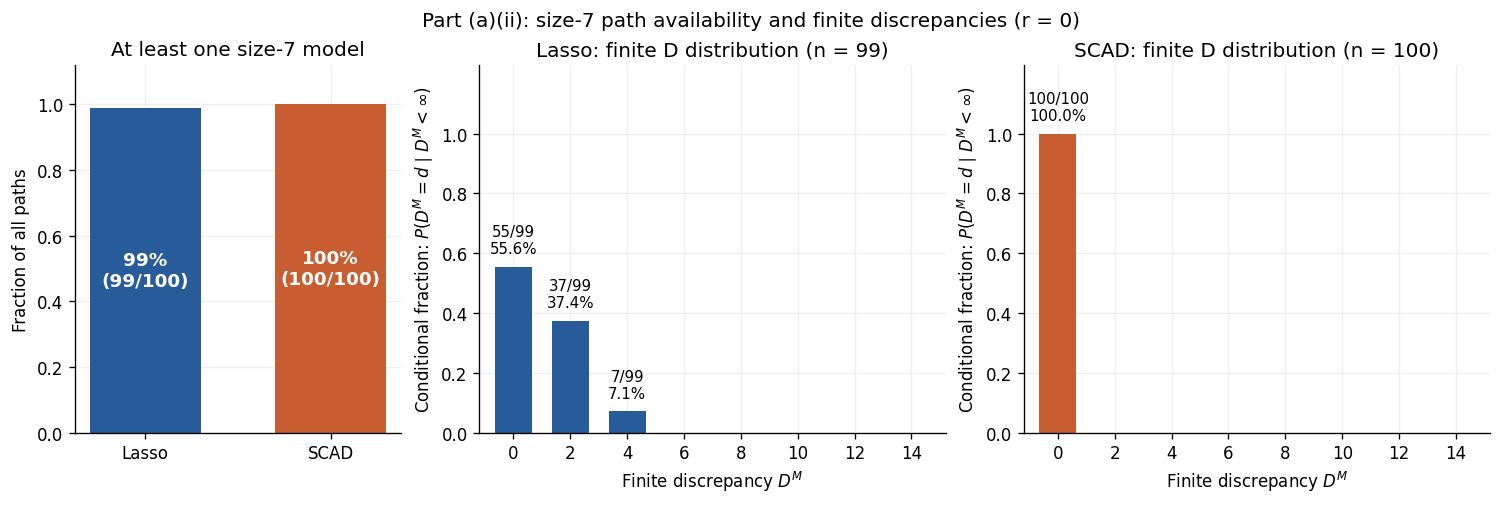

In [68]:
# Part (a)(ii): availability is unconditional; finite-D distributions are conditional.
availability_a = summary_table(results_a).set_index('method')
finite_a = finite_distribution(results_a)
fig, axes = plt.subplots(1, 3, figsize=(12.4, 4.1),
                         gridspec_kw={'width_ratios': [1.05, 1.5, 1.5]},
                         layout='constrained')

for position, method in enumerate(METHODS):
    row = availability_a.loc[method]
    fraction = row['size7_fraction']
    axes[0].bar(position, fraction, width=0.6, color=COLORS[method])
    axes[0].text(position, fraction/2,
                 f"{fraction:.0%}\n({int(row['size7_count'])}/{int(row['B'])})",
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)
axes[0].set(xticks=range(len(METHODS)), xticklabels=METHODS,
            ylim=(0, 1.12), yticks=np.linspace(0, 1, 6),
            ylabel='Fraction of all paths', title='At least one size-7 model')

for ax, method in zip(axes[1:], METHODS):
    group = finite_a.loc[finite_a.method == method].sort_values('D')
    n_finite = int(availability_a.loc[method, 'size7_count'])
    if n_finite:
        ax.bar(group.D, group.conditional_probability, width=1.3, color=COLORS[method])
        for row in group.itertuples(index=False):
            if row.count:
                ax.text(row.D, row.conditional_probability + 0.035,
                        f'{row.count}/{n_finite}\n{row.conditional_probability:.1%}',
                        ha='center', va='bottom', fontsize=9)
    else:
        ax.text(0.5, 0.5, 'No finite discrepancies', ha='center', va='center',
                transform=ax.transAxes)
    ax.set(xticks=range(0, 15, 2), xlim=(-1.2, 15.2), ylim=(0, 1.23),
           yticks=np.linspace(0, 1, 6), xlabel=r'Finite discrepancy $D^M$',
           ylabel=r'Conditional fraction: $P(D^M=d\mid D^M<\infty)$',
           title=f'{method}: finite D distribution (n = {n_finite})')
fig.suptitle('Part (a)(ii): size-7 path availability and finite discrepancies (r = 0)', fontsize=12)
plt.show()

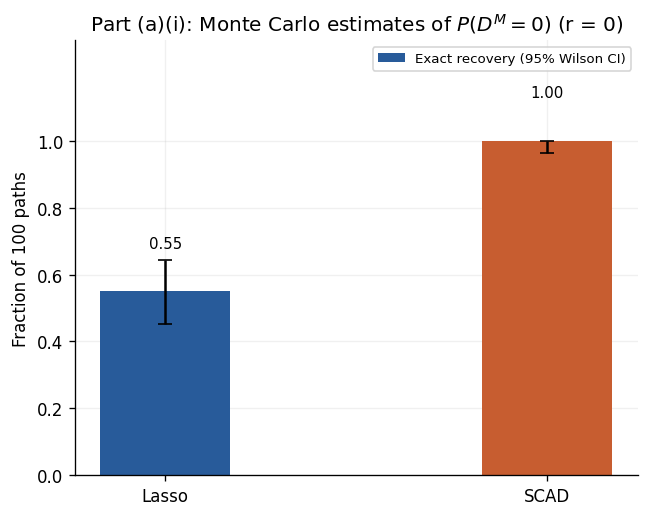

In [69]:
sa = summary_table(results_a).set_index('method')
x = np.arange(len(METHODS))
width = 0.34
fig, ax = plt.subplots(figsize=(5.3,4.2), layout='constrained')
phat = sa.loc[list(METHODS), 'recovery'].to_numpy()
low = sa.loc[list(METHODS), 'CI_low'].to_numpy()
high = sa.loc[list(METHODS), 'CI_high'].to_numpy()
ax.bar(x, phat, width, color=[COLORS[m] for m in METHODS],
       yerr=np.vstack([np.maximum(0,phat-low),np.maximum(0,high-phat)]), capsize=4,
       label='Exact recovery (95% Wilson CI)')
# available = sa.loc[list(METHODS),'size7_fraction'].to_numpy()
# ax.bar(x+width/2, available, width, color='#C5CCD4', label='Path contains a size-7 model')
for xpos, values in [(x, phat)]:
# for xpos, values in [(x-width/2, phat),(x+width/2, available)]:
    for xp,v in zip(xpos,values):
        ax.text(xp,v+0.13,f'{v:.2f}',ha='center',fontsize=9)
ax.set(xticks=x,xticklabels=METHODS,ylim=(0,1.30),ylabel='Fraction of 100 paths',
       title='Part (a)(i): Monte Carlo estimates of $P(D^M=0)$ (r = 0)')
ax.set_yticks(np.linspace(0,1,6))
ax.legend(loc='upper right',fontsize=8)
plt.show()

In [70]:
for row in summary_table(results_a).itertuples(index=False):
    display(Markdown(f'**{row.method}:** {row.exact_count}/{row.B} exact recoveries '
                     f'({row.recovery:.3f}, MC SE {row.MCSE:.3f}; '
                     f'95% Wilson CI [{row.CI_low:.3f}, {row.CI_high:.3f}]). '
                     f'{row.size7_count}/{row.B} paths contain a size-seven model.'))

**Lasso:** 55/100 exact recoveries (0.550, MC SE 0.050; 95% Wilson CI [0.452, 0.644]). 99/100 paths contain a size-seven model.

**SCAD:** 100/100 exact recoveries (1.000, MC SE 0.000; 95% Wilson CI [0.963, 1.000]). 100/100 paths contain a size-seven model.

**Interpretation.** Exact support recovery requires every one of the seven signals and none of the 993 irrelevant variables to be selected, simultaneously. A model can predict well while missing a weak signal or including an extra variable with a small coefficient. Prediction depends on the fitted values $X\widehat\beta$; support recovery is a discrete criterion sensitive to small coefficient changes. Even when a path contains the true support, finding that tuning value without knowing the truth is a separate problem. The empirical results above describe path availability rather than cross-validated performance.

## Part (b) · Correlated predictors: $r=0.5$

Repeat the same experiment with independent data streams at $r=0.5$. Reuse the completed $r=0$ experiment for comparison. For paths that contain a size-seven model, report the mean, across paths, of the **minimum** FP and FN on that path. For paths without such a model the minima are undefined; their frequency remains visible in the summary.

In [71]:
results_b = run_experiment(0.5)
summary_b = show_summary(results_b)
distribution_b = finite_distribution(results_b)

r=0.50: 20/100 data sets; 11.1 s elapsed
r=0.50: 40/100 data sets; 20.4 s elapsed
r=0.50: 60/100 data sets; 30.4 s elapsed
r=0.50: 80/100 data sets; 40.4 s elapsed
r=0.50: 100/100 data sets; 49.9 s elapsed


,r,method,B,exact_count,P(exact),MC SE,CI_low,CI_high,size7_count,P(size 7),Mean min FP | size 7,Mean min FN | size 7
0,0.5,Lasso,100,27,0.27,0.0444,0.1927,0.3643,94,0.94,0.9681,0.9681
1,0.5,SCAD,100,99,0.99,0.0099,0.9455,0.9982,99,0.99,0.0000,0.0000


### Part (b)(ii) · Graphical report

The presentation follows part (a): the left panel shows the fraction of **all** paths that contain at least one size-$s_0=7$ model, and the other two panels show the empirical distributions of finite $D^M$. Each nonzero bar reports a count and a percentage. The finite-discrepancy denominators appear in the panel titles; paths with $D^M=\infty$ are excluded only from those conditional distributions.

The next graph reports unconditional exact recovery with the same pointwise 95% Wilson intervals used in part (a). A zero conditional discrepancy does not imply that every path recovered the support: paths that never reach size seven remain failures in the unconditional estimate.

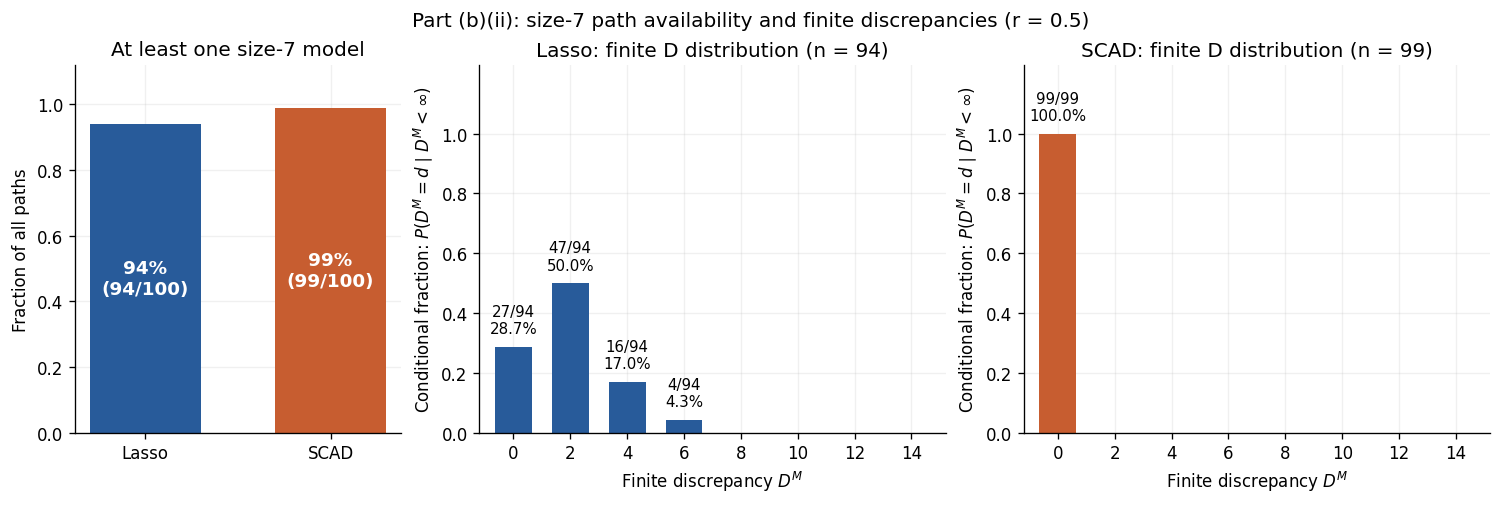

In [72]:
# Part (b)(ii): availability is unconditional; finite-D distributions are conditional.
availability_b = summary_table(results_b).set_index('method')
finite_b = finite_distribution(results_b)
fig, axes = plt.subplots(1, 3, figsize=(12.4, 4.1),
                         gridspec_kw={'width_ratios': [1.05, 1.5, 1.5]},
                         layout='constrained')

for position, method in enumerate(METHODS):
    row = availability_b.loc[method]
    fraction = row['size7_fraction']
    axes[0].bar(position, fraction, width=0.6, color=COLORS[method])
    axes[0].text(position, fraction/2,
                 f"{fraction:.0%}\n({int(row['size7_count'])}/{int(row['B'])})",
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)
axes[0].set(xticks=range(len(METHODS)), xticklabels=METHODS,
            ylim=(0, 1.12), yticks=np.linspace(0, 1, 6),
            ylabel='Fraction of all paths', title='At least one size-7 model')

for ax, method in zip(axes[1:], METHODS):
    group = finite_b.loc[finite_b.method == method].sort_values('D')
    n_finite = int(availability_b.loc[method, 'size7_count'])
    if n_finite:
        ax.bar(group.D, group.conditional_probability, width=1.3, color=COLORS[method])
        for row in group.itertuples(index=False):
            if row.count:
                ax.text(row.D, row.conditional_probability + 0.035,
                        f'{row.count}/{n_finite}\n{row.conditional_probability:.1%}',
                        ha='center', va='bottom', fontsize=9)
    else:
        ax.text(0.5, 0.5, 'No finite discrepancies', ha='center', va='center',
                transform=ax.transAxes)
    ax.set(xticks=range(0, 15, 2), xlim=(-1.2, 15.2), ylim=(0, 1.23),
           yticks=np.linspace(0, 1, 6), xlabel=r'Finite discrepancy $D^M$',
           ylabel=r'Conditional fraction: $P(D^M=d\mid D^M<\infty)$',
           title=f'{method}: finite D distribution (n = {n_finite})')
fig.suptitle('Part (b)(ii): size-7 path availability and finite discrepancies (r = 0.5)', fontsize=12)
plt.show()

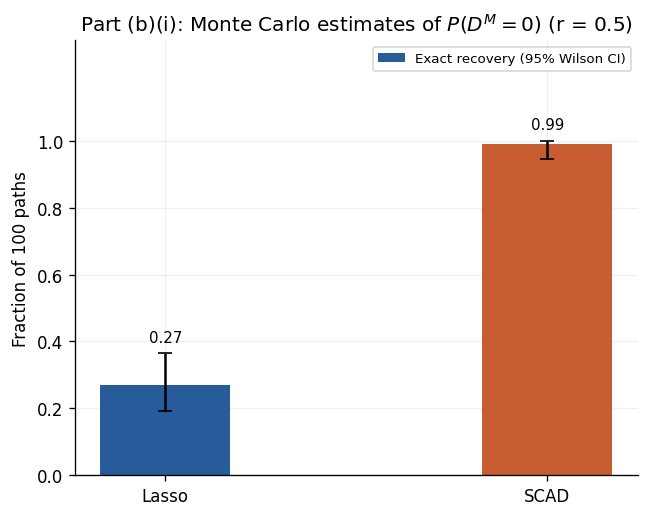

In [73]:
# Match the exact-recovery presentation in part (a).
sb = summary_table(results_b).set_index('method')
x = np.arange(len(METHODS))
width = 0.34
fig, ax = plt.subplots(figsize=(5.3,4.2), layout='constrained')
phat = sb.loc[list(METHODS), 'recovery'].to_numpy()
low = sb.loc[list(METHODS), 'CI_low'].to_numpy()
high = sb.loc[list(METHODS), 'CI_high'].to_numpy()
ax.bar(x, phat, width, color=[COLORS[m] for m in METHODS],
       yerr=np.vstack([np.maximum(0,phat-low),np.maximum(0,high-phat)]), capsize=4,
       label='Exact recovery (95% Wilson CI)')
for xp, value, upper in zip(x, phat, high):
    ax.text(xp, max(value,upper)+0.035, f'{value:.2f}', ha='center', fontsize=9)
ax.set(xticks=x, xticklabels=METHODS, ylim=(0,1.30),
       ylabel=f'Fraction of {N_REP} paths',
       title='Part (b)(i): Monte Carlo estimates of $P(D^M=0)$ (r = 0.5)')
ax.set_yticks(np.linspace(0,1,6))
ax.legend(loc='upper right',fontsize=8)
plt.show()

In [74]:
for row in summary_table(results_b).itertuples(index=False):
    display(Markdown(f'**{row.method}:** {row.exact_count}/{row.B} exact recoveries '
                     f'({row.recovery:.3f}, MC SE {row.MCSE:.3f}; '
                     f'95% Wilson CI [{row.CI_low:.3f}, {row.CI_high:.3f}]). '
                     f'{row.size7_count}/{row.B} paths contain a size-seven model.'))

**Lasso:** 27/100 exact recoveries (0.270, MC SE 0.044; 95% Wilson CI [0.193, 0.364]). 94/100 paths contain a size-seven model.

**SCAD:** 99/100 exact recoveries (0.990, MC SE 0.010; 95% Wilson CI [0.946, 0.998]). 99/100 paths contain a size-seven model.

### Comparison with part (a): recovery and selection errors

The tables compare $r=0$ and $r=0.5$, retaining the Monte Carlo standard errors, pointwise confidence intervals, and the number of paths that reach size seven. The FP/FN graph reports the **average pathwise minimum**, conditional on a size-seven model existing. Its error bars show $\pm1$ Monte Carlo standard error of that conditional mean.

For every size-seven model, FP equals FN because the true support also has size seven. Their pathwise minima, and therefore the two displayed means, are equal. Paths without a size-seven model are counted in the availability and recovery reports; their FP/FN minima are undefined and excluded from these conditional means.

In [75]:
comparison_ab = pd.concat([results_a,results_b],ignore_index=True)
summary_ab = show_summary(comparison_ab)

# Across-path SEs for conditional mean minimum FP and FN (conditional on availability).
conditional_rows=[]
for (r,method),group in comparison_ab.groupby(['r','method']):
    finite = group.loc[group.has_size7]
    m = len(finite)
    conditional_rows.append(dict(r=r,method=method,finite_paths=m,
        mean_min_FP=finite.min_FP.mean(),mean_min_FN=finite.min_FN.mean(),
        SE_conditional_mean_FP=finite.min_FP.std(ddof=1)/np.sqrt(m) if m>1 else np.nan,
        SE_conditional_mean_FN=finite.min_FN.std(ddof=1)/np.sqrt(m) if m>1 else np.nan))
conditional_summary = pd.DataFrame(conditional_rows)
display(conditional_summary.round(4))

,r,method,B,exact_count,P(exact),MC SE,CI_low,CI_high,size7_count,P(size 7),Mean min FP | size 7,Mean min FN | size 7
0,0.0,Lasso,100,55,0.55,0.0497,0.4524,0.6439,99,0.99,0.5152,0.5152
1,0.0,SCAD,100,100,1.00,0.0000,0.9630,1.0000,100,1.00,0.0000,0.0000
2,0.5,Lasso,100,27,0.27,0.0444,0.1927,0.3643,94,0.94,0.9681,0.9681
3,0.5,SCAD,100,99,0.99,0.0099,0.9455,0.9982,99,0.99,0.0000,0.0000


,r,method,finite_paths,mean_min_FP,mean_min_FN,SE_conditional_mean_FP,SE_conditional_mean_FN
0,0.0,Lasso,99,0.5152,0.5152,0.0632,0.0632
1,0.0,SCAD,100,0.0000,0.0000,0.0000,0.0000
2,0.5,Lasso,94,0.9681,0.9681,0.0821,0.0821
3,0.5,SCAD,99,0.0000,0.0000,0.0000,0.0000


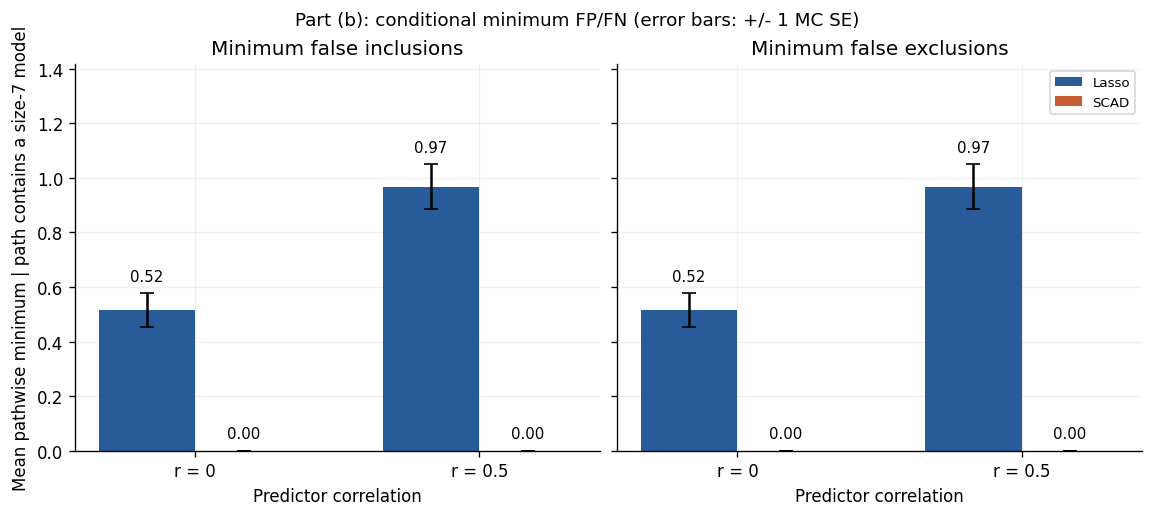

In [76]:
# Compare the part-(b) metrics across r=0 and r=0.5.
# Error bars are +/- one Monte Carlo SE of each conditional mean.
correlations = (0., 0.5)
x = np.arange(len(correlations))
width = 0.34
fig, axes = plt.subplots(1, 2, figsize=(9.5,4.2), sharey=True, layout='constrained')
for ax, metric, se_column, title in [
    (axes[0], 'mean_min_FP', 'SE_conditional_mean_FP', 'Minimum false inclusions'),
    (axes[1], 'mean_min_FN', 'SE_conditional_mean_FN', 'Minimum false exclusions'),
]:
    for method_index, method in enumerate(METHODS):
        group = conditional_summary.loc[conditional_summary.method == method].set_index('r').reindex(correlations)
        values = group[metric].to_numpy()
        errors = group[se_column].to_numpy()
        positions = x+(method_index-0.5)*width
        ax.bar(positions, values, width, yerr=errors, capsize=4,
               color=COLORS[method], label=method)
        for position, value, error in zip(positions, values, errors):
            if np.isfinite(value):
                ax.text(position, value+(error if np.isfinite(error) else 0)+0.045,
                        f'{value:.2f}', ha='center', fontsize=9)
    ax.set(xticks=x, xticklabels=['r = 0','r = 0.5'],
           xlabel='Predictor correlation', title=title)
axes[0].set_ylabel('Mean pathwise minimum | path contains a size-7 model')
axes[0].set_ylim(0, 1.35*max(0.2, np.nanmax(
    conditional_summary.mean_min_FP+conditional_summary.SE_conditional_mean_FP)))
axes[1].legend(fontsize=8)
fig.suptitle('Part (b): conditional minimum FP/FN (error bars: +/- 1 MC SE)', fontsize=11)
plt.show()

In [77]:
st = summary_table(comparison_ab).set_index(['r','method'])
for method in METHODS:
    base, corr = st.loc[(0.,method)], st.loc[(0.5,method)]
    display(Markdown(
        f'**{method}:** exact-recovery frequency changes from {base.recovery:.2f} '
        f'at r=0 to {corr.recovery:.2f} at r=0.5 '
        f'({100*(corr.recovery-base.recovery):+.1f} percentage points). '
        f'At r=0.5, {int(corr.size7_count)}/100 paths reach size seven, and '
        f'the conditional mean minimum FP and FN are both {corr.mean_min_FP:.3f}.'
    ))

**Lasso:** exact-recovery frequency changes from 0.55 at r=0 to 0.27 at r=0.5 (-28.0 percentage points). At r=0.5, 94/100 paths reach size seven, and the conditional mean minimum FP and FN are both 0.968.

**SCAD:** exact-recovery frequency changes from 1.00 at r=0 to 0.99 at r=0.5 (-1.0 percentage points). At r=0.5, 99/100 paths reach size seven, and the conditional mean minimum FP and FN are both 0.000.

**Why correlation affects support stability.** With equicorrelation, the population variance of the difference of two predictors is $\operatorname{Var}(X_j-X_k)=2(1-r)$. Increasing $r$ makes these differences less variable. Replacing a coefficient $b$ on one variable with the same coefficient on another then changes prediction by a term with variance $2b^2(1-r)$, which can be modest even though the selected variable changes. The common component can be represented by many different combinations of columns. Identifying the distinct signal coordinates becomes harder, especially for small or opposing signals; sample perturbations can change which variables are selected.

SCAD reduces shrinkage for large coefficients, but a nonconvex path can also jump between supports or remain on a less favorable stationary branch. The size-seven frequency distinguishes failure to visit that model size from visiting an incorrect size-seven model. Finite-sample recovery need not decrease monotonically at every adjacent correlation, and 100 replications leave visible Monte Carlo uncertainty.

### Illustrative complete paths (one data set, not an additional Monte Carlo estimate)

The next figure shows all 100 tuning values for the first $r=0.5$ replication. True signal coordinates are colored; other coordinates are gray. The horizontal axis is the log-scaled fraction $\lambda/\lambda_{\max}$, decreasing from left to right. Supports are counted with the same $10^{-6}$ threshold used for all tables.

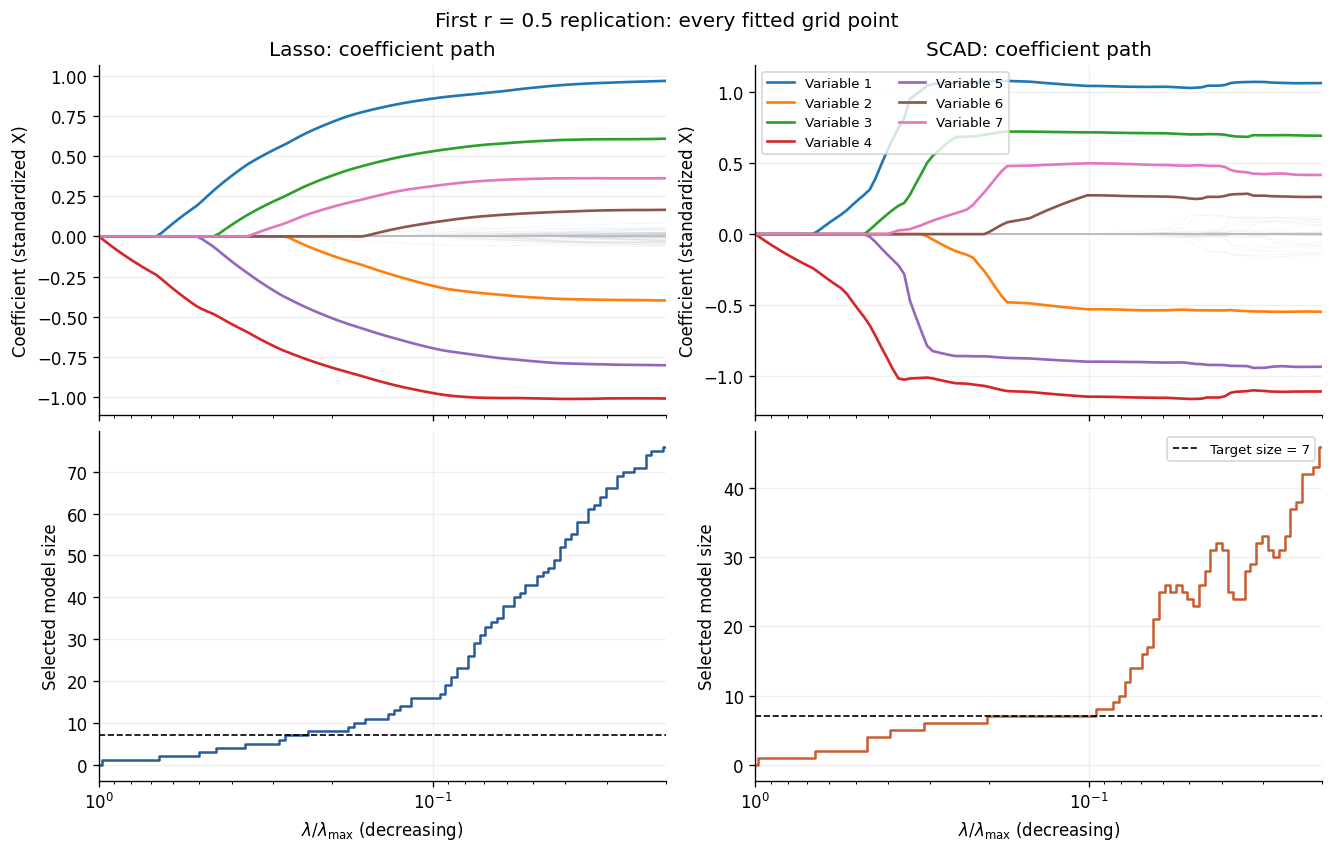

In [78]:
example = example_cache[0.5]
ratio = example['lambdas']/example['lambdas'][0]
fig,axes = plt.subplots(2,2,figsize=(11,7),sharex=True,layout='constrained')
signal_colors = plt.get_cmap('tab10').colors
for j,method in enumerate(METHODS):
    B = example['fits'][method]['coef']
    axes[0,j].plot(ratio,B[S0_SIZE:,:].T,color='#B7BDC5',alpha=.12,lw=.6)
    for k in S0:
        axes[0,j].plot(ratio,B[k,:],color=signal_colors[k],lw=1.6,label=f'Variable {k+1}')
    axes[0,j].set(title=f'{method}: coefficient path',ylabel='Coefficient (standardized X)')
    axes[1,j].step(ratio,(np.abs(B)>SUPPORT_TOL).sum(axis=0),where='mid',color=COLORS[method])
    axes[1,j].axhline(S0_SIZE,color='black',ls='--',lw=1,label='Target size = 7')
    axes[1,j].set(xlabel=r'$\lambda/\lambda_{\max}$ (decreasing)',ylabel='Selected model size')
    for ax in axes[:,j]:
        ax.set_xscale('log'); ax.set_xlim(1.,MIN_RATIO)
axes[0,1].legend(ncol=2,fontsize=8)
axes[1,1].legend(fontsize=8)
fig.suptitle('First r = 0.5 replication: every fitted grid point')
plt.show()

## Part (c) · Collinearity profile and penalty interpretation

Complete the $r\in\{0,0.25,0.50,0.75\}$ profile with 100 replications per correlation. The $r=0$ and $r=0.5$ samples from parts (a) and (b) are reused, so their results agree across parts. Methods are paired on each data set; samples at different correlations are independent. The intervals are **pointwise**, not simultaneous bands or confidence intervals for between-method differences.

r=0.25: 20/100 data sets; 2.9 s elapsed
r=0.25: 40/100 data sets; 5.8 s elapsed
r=0.25: 60/100 data sets; 8.8 s elapsed
r=0.25: 80/100 data sets; 11.5 s elapsed
r=0.25: 100/100 data sets; 14.3 s elapsed
r=0.75: 20/100 data sets; 44.5 s elapsed
r=0.75: 40/100 data sets; 95.2 s elapsed
r=0.75: 60/100 data sets; 148.3 s elapsed
r=0.75: 80/100 data sets; 198.2 s elapsed
r=0.75: 100/100 data sets; 246.3 s elapsed


,r,method,B,exact_count,P(exact),MC SE,CI_low,CI_high,size7_count,P(size 7),Mean min FP | size 7,Mean min FN | size 7
0,0.00,Lasso,100,55,0.55,0.0497,0.4524,0.6439,99,0.99,0.5152,0.5152
1,0.00,SCAD,100,100,1.00,0.0000,0.9630,1.0000,100,1.00,0.0000,0.0000
2,0.25,Lasso,100,36,0.36,0.0480,0.2727,0.4576,93,0.93,0.7419,0.7419
3,0.25,SCAD,100,100,1.00,0.0000,0.9630,1.0000,100,1.00,0.0000,0.0000
4,0.50,Lasso,100,27,0.27,0.0444,0.1927,0.3643,94,0.94,0.9681,0.9681
5,0.50,SCAD,100,99,0.99,0.0099,0.9455,0.9982,99,0.99,0.0000,0.0000
6,0.75,Lasso,100,7,0.07,0.0255,0.0343,0.1375,85,0.85,1.6353,1.6353
7,0.75,SCAD,100,81,0.81,0.0392,0.7222,0.8749,92,0.92,0.1196,0.1196


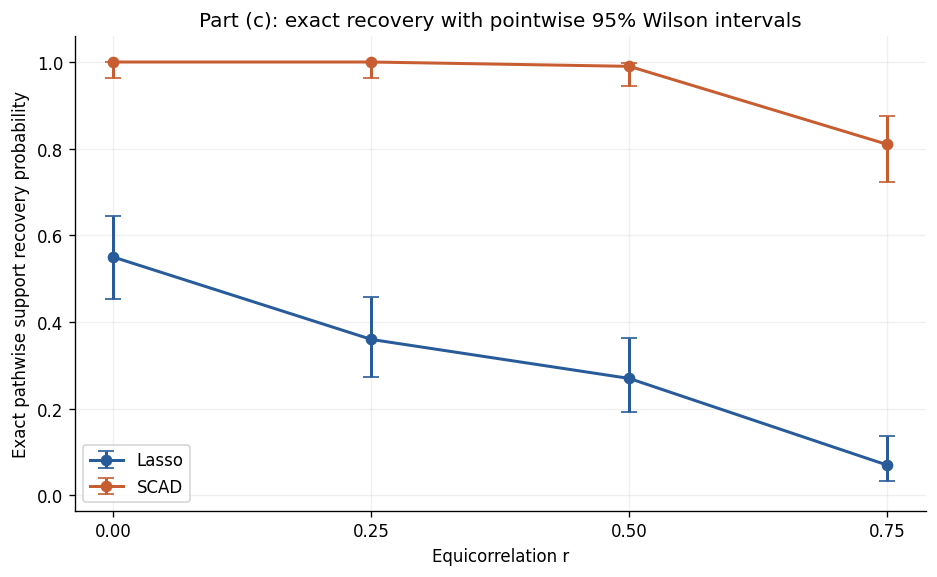

In [79]:
for r in R_GRID:
    run_experiment(r)
all_results = pd.concat([experiment_cache[r] for r in R_GRID],ignore_index=True)
profile = summary_table(all_results)
show_summary(all_results)

fig,ax = plt.subplots(figsize=(7.7,4.7),layout='constrained')
for method in METHODS:
    group = profile.loc[profile.method==method].sort_values('r')
    estimates = group.recovery.to_numpy()
    interval = np.vstack([np.maximum(0,estimates-group.CI_low.to_numpy()),
                          np.maximum(0,group.CI_high.to_numpy()-estimates)])
    ax.errorbar(group.r,estimates,yerr=interval,marker='o',lw=1.8,capsize=5,
                color=COLORS[method],label=method)
ax.set(xlabel='Equicorrelation r',ylabel='Exact pathwise support recovery probability',
       xticks=R_GRID,ylim=(-.035,1.06),
       title='Part (c): exact recovery with pointwise 95% Wilson intervals')
ax.legend()
plt.show()

In [80]:
for method in METHODS:
    group = profile.loc[profile.method==method].sort_values('r')
    values = ', '.join(f'r={row.r:.2f}: {row.recovery:.2f}' for row in group.itertuples())
    display(Markdown(f'**Observed {method} profile:** {values}.'))
display(Markdown('The plotted profile estimates this finite-grid, warm-start algorithm at n=100 '
                 'and p=1000. It is not an asymptotic oracle-property demonstration.'))

**Observed Lasso profile:** r=0.00: 0.55, r=0.25: 0.36, r=0.50: 0.27, r=0.75: 0.07.

**Observed SCAD profile:** r=0.00: 1.00, r=0.25: 1.00, r=0.50: 0.99, r=0.75: 0.81.

The plotted profile estimates this finite-grid, warm-start algorithm at n=100 and p=1000. It is not an asymptotic oracle-property demonstration.

### Penalty shapes at a representative $\lambda$

Use the deterministic illustrative value $\lambda=0.2$, with $a=3.7$. The left panel includes the requested Lasso penalty $\lambda|\beta|$ and the SCAD penalty for comparison. The right panel shows the requested SCAD derivative as a function of magnitude $t\ge0$, with the constant Lasso derivative for reference. The vertical markers identify $\lambda$ and $a\lambda$.

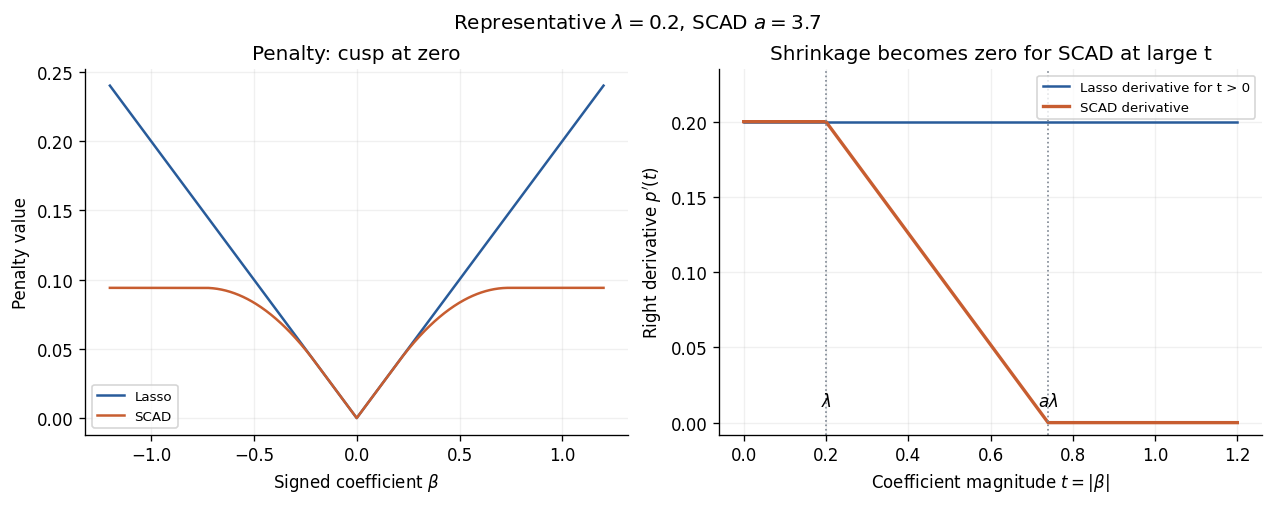

SCAD penalty/derivative consistency check passed.


In [81]:
def scad_penalty(t, lam, a=A_SCAD):
    t = np.asarray(t)
    return np.where(t<=lam,lam*t,
                    np.where(t<=a*lam,(-t*t+2*a*lam*t-lam*lam)/(2*(a-1)),
                             (a+1)*lam*lam/2))


def scad_derivative(t, lam, a=A_SCAD):
    t = np.asarray(t)
    return np.where(t<=lam,lam,np.maximum(a*lam-t,0)/(a-1))

lambda_rep = 0.2
signed_beta = np.linspace(-1.2,1.2,801)
t = np.linspace(0,1.2,601)
fig,axes = plt.subplots(1,2,figsize=(10.5,4.1),layout='constrained')
axes[0].plot(signed_beta,lambda_rep*np.abs(signed_beta),color=COLORS['Lasso'],label='Lasso')
axes[0].plot(signed_beta,scad_penalty(np.abs(signed_beta),lambda_rep),color=COLORS['SCAD'],label='SCAD')
axes[0].set(xlabel=r'Signed coefficient $\beta$',ylabel='Penalty value',title='Penalty: cusp at zero')
axes[1].plot(t,np.full_like(t,lambda_rep),color=COLORS['Lasso'],label='Lasso derivative for t > 0')
axes[1].plot(t,scad_derivative(t,lambda_rep),color=COLORS['SCAD'],lw=2,label='SCAD derivative')
for value,label in [(lambda_rep,r'$\lambda$'),(A_SCAD*lambda_rep,r'$a\lambda$')]:
    axes[1].axvline(value,color='#7B8490',ls=':',lw=1)
    axes[1].text(value,.011,label,ha='center',fontsize=10)
axes[1].set(xlabel=r'Coefficient magnitude $t=|\beta|$',ylabel=r'Right derivative $p^{\prime}(t)$',
            title='Shrinkage becomes zero for SCAD at large t',ylim=(-.008,.235))
for ax in axes: ax.legend(fontsize=8)
fig.suptitle(r'Representative $\lambda=0.2$, SCAD $a=3.7$')
plt.show()

# Independent consistency check: derivative of the displayed penalty away from its knots.
probe = np.array([.05,.12,.3,.55,.9])
h = 1e-6
assert np.allclose((scad_penalty(probe+h,lambda_rep)-scad_penalty(probe-h,lambda_rep))/(2*h),
                   scad_derivative(probe,lambda_rep),atol=1e-9)
print('SCAD penalty/derivative consistency check passed.')

**Sparsity at zero.** The singularity here is a cusp (nondifferentiability), not an infinite derivative: both penalties have right derivative $\lambda$ at magnitude zero, and the signed penalty has left and right derivatives $-\lambda$ and $+\lambda$. Its subgradient at zero contains $[-\lambda,\lambda]$. Thus a range of partial residual correlations can satisfy the optimality condition with a coefficient exactly zero. The threshold update explicitly produces those zeros.

**Shrinkage bias.** Lasso applies slope $\lambda$ to every nonzero magnitude, so it keeps shrinking large coefficients. SCAD's slope decreases after $\lambda$ and becomes zero above $a\lambda$; a sufficiently large coefficient receives no direct penalty gradient. In an orthogonal problem it then equals the unpenalized coordinate estimate. Correlated coefficients remain jointly coupled, so this mechanism does not ensure unbiased estimates or perfect selection in every sample.

**Nonconvexity and initialization.** The decreasing derivative creates negative penalty curvature on $(\lambda,a\lambda)$. The total SCAD objective can consequently have multiple stationary solutions; cyclic coordinate descent can depend on initialization, coordinate order, and the direction and spacing of the tuning path. Warm starts define a reproducible branch, not a proof of global optimization. The following diagnostic compares three starting points on a single high-correlation data set without changing the Monte Carlo protocol.

In [82]:
local_example = example_cache[0.75]
local_X,local_y = local_example['X'],local_example['y']
local_lambdas = local_example['lambdas']
k = int(np.argmin(np.abs(np.log(local_lambdas/local_lambdas[0])-np.log(.08))))
lam = local_lambdas[k]
starts = {
    'Warm path solution': local_example['fits']['SCAD']['coef'][:,k],
    'Zero vector': np.zeros(P),
    'Lasso at the same lambda': local_example['fits']['Lasso']['coef'][:,k],
}
local_rows=[]
for label,initial in starts.items():
    B,sweeps,kkt,ok,increase,start_obj,end_obj = solve_one(local_X,local_y,lam,1,initial,**SOLVER)
    assert ok and kkt <= SOLVER['kkt_tol']*max(1.,lam)
    residual = local_y-np.einsum('ij,j->i',local_X,B)
    objective = .5*np.mean(residual**2)+scad_penalty(np.abs(B),lam).sum()
    local_rows.append(dict(initialization=label,lambda_ratio=lam/local_lambdas[0],
        objective=objective,size=int((np.abs(B)>SUPPORT_TOL).sum()),
        max_KKT=kkt,sweeps=sweeps,
        distance_to_warm=np.max(np.abs(B-starts['Warm path solution']))))
local_diagnostic = pd.DataFrame(local_rows)
display(local_diagnostic)
display(Markdown('Agreement of these starts on this one example would not establish uniqueness. '
                 'Disagreement would provide a direct example of initialization dependence. '
                 'These supplemental fits are excluded from all Monte Carlo recovery counts.'))

,initialization,lambda_ratio,objective,size,max_KKT,sweeps,distance_to_warm
0,Warm path solution,0.07974,0.049527,16,5.396412e-08,1,1.992876e-08
1,Zero vector,0.07974,0.044522,14,4.837225e-08,1869,2.645237e-01
2,Lasso at the same lambda,0.07974,0.050136,14,3.310944e-08,808,1.657424e-01


Agreement of these starts on this one example would not establish uniqueness. Disagreement would provide a direct example of initialization dependence. These supplemental fits are excluded from all Monte Carlo recovery counts.

**Observed initialization sensitivity.** On this data set, the warm path gives 16 selected variables and objective 0.04953, while a zero start gives 14 variables and a lower objective of 0.04452. The same-lambda Lasso start gives another stationary solution, with objective 0.05014. All three satisfy the stated numerical stationarity tolerance. This directly illustrates that a converged SCAD path can depend on initialization; convergence alone does not certify the globally best solution. The reported Monte Carlo results consistently use the specified decreasing warm-start path.

## Final validation and reproducibility record

The next checks enforce all required replication counts, complete paths, convergence tolerances, metric identities, and consistency between parts. Independent NumPy KKT calculations audit every path point in the first replication at each correlation. Lasso duality gaps on those audit paths also check global convex optimality. SCAD has no comparable global certificate here.

In [83]:
assert len(all_results) == len(R_GRID)*N_REP*len(METHODS)
assert (all_results.groupby(['r','method']).size() == N_REP).all()
assert all_results[['r','replication','method']].duplicated().sum() == 0
assert all_results.max_scaled_KKT.max() <= SOLVER['kkt_tol']*1.02
assert all_results.max_sweeps.max() < SOLVER['max_sweeps']
finite = all_results.loc[all_results.has_size7]
assert finite.D.isin(range(0,15,2)).all()
assert np.allclose(finite.D,2*finite.min_FP)
assert np.allclose(finite.min_FP,finite.min_FN)
assert np.isinf(all_results.loc[~all_results.has_size7,'D']).all()
assert (all_results.exact == (all_results.D == 0)).all()
assert (all_results.loc[~all_results.has_size7,['min_FP','min_FN']].isna()).all().all()
pd.testing.assert_frame_equal(experiment_cache[0.],results_a)
pd.testing.assert_frame_equal(experiment_cache[0.5],results_b)

# Repeat the same random stream and check equality, without changing any stored result.
X_repeat,y_repeat,_ = simulate(.5,replication=0,seed=MASTER_SEED,n=N,p=P)
assert np.array_equal(X_repeat,example_cache[.5]['X'])
assert np.array_equal(y_repeat,example_cache[.5]['y'])
for method in METHODS:
    repeated = fit_path(X_repeat,y_repeat,lambda_grid(X_repeat,y_repeat),method,**SOLVER)
    assert np.allclose(repeated['coef'],example_cache[.5]['fits'][method]['coef'],atol=1e-12,rtol=0)

optimization_summary = all_results.groupby(['r','method']).agg(
    maximum_scaled_KKT=('max_scaled_KKT','max'),
    maximum_sweeps_at_one_lambda=('max_sweeps','max'),
    maximum_objective_increase=('max_objective_increase','max'))
display(optimization_summary)
display(pd.DataFrame(audit_records))
print(f'PASS: {len(R_GRID)*N_REP} independent data sets, '
      f'{len(all_results)} full paths, {len(all_results)*N_LAMBDA:,} fitted grid points.')
print('All convergence, metric, scalar-reference, Lasso-reference, and reproducibility checks passed.')

maximum_scaled_KKT  maximum_sweeps_at_one_lambda  maximum_objective_increase
r    method                                                                              
0.00 Lasso         2.163035e-08                           568                1.332268e-15
     SCAD          1.986175e-08                          3185                1.332268e-15
0.25 Lasso         6.269347e-08                           607                1.332268e-15
     SCAD          5.344540e-08                          2417                1.332268e-15
0.50 Lasso         9.999331e-08                          3463                6.661338e-16
     SCAD          9.942801e-08                          4457                6.661338e-16
0.75 Lasso         9.999984e-08                         26997                3.330669e-16
     SCAD          9.999894e-08                          5115                3.330669e-16

,r,method,max_scaled_KKT,max_Lasso_dual_gap
0,0.00,Lasso,1.779578e-08,6.610761e-08
1,0.00,SCAD,1.171459e-08,NaN
2,0.50,Lasso,6.691956e-08,3.950838e-07
3,0.50,SCAD,8.368049e-08,NaN
4,0.25,Lasso,3.908747e-08,2.137850e-07
5,0.25,SCAD,2.106903e-08,NaN
6,0.75,Lasso,9.999353e-08,6.547930e-07
7,0.75,SCAD,9.979106e-08,NaN


PASS: 400 independent data sets, 800 full paths, 80,000 fitted grid points.
All convergence, metric, scalar-reference, Lasso-reference, and reproducibility checks passed.


### Results available for reuse

`all_results` contains one row per data set and method, including every discrepancy, missing-size-seven indicator, minimum FP/FN, and optimization diagnostic. `profile` contains the aggregate recovery estimates, Monte Carlo SEs, and confidence limits. `finite_distribution(all_results)` gives all finite discrepancy distributions. The optional cell below exports these tables next to the notebook when uncommented; saving files is not needed to reproduce its displayed outputs.

In [84]:
# Optional CSV export after a complete run:
# all_results.to_csv('Problem1_replication_metrics.csv',index=False)
# profile.to_csv('Problem1_summary.csv',index=False)
# finite_distribution(all_results).to_csv('Problem1_finite_discrepancies.csv',index=False)

### References and AI-use disclosure

- The supplied **DSO 607 Homework 3, Fall 2026**, Problem 1, equations (1)–(11), defines the experimental design and evaluation criterion.
- Fan, J. and Li, R. (2001). *Variable selection via nonconcave penalized likelihood and its oracle properties*. JASA 96, 1348–1360. SCAD penalty as specified in the assignment.
- [Breheny, P. and Huang, J. (2011). *Coordinate descent algorithms for nonconvex penalized regression, with applications to biological feature selection*. Annals of Applied Statistics 5, 232–253](https://arxiv.org/abs/1104.2748). Scalar updates and computational convergence considerations.
- [scikit-learn: Lasso objective and implementation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html). Independent reference for the Lasso numerical tests.

**AI-use disclosure:** I used OpenAI Codex (GPT-6.1. Sol, Medium) to assist with developing and checking the Python implementation for Problem 1, understanding the conditional correlation for Problem 2(iii), and polishing the written explanations and solver specifications. This assistance contributed to the notebook code and explanations and the corresponding PDF solutions. I reviewed the code and mathematical arguments, examined the numerical validation and convergence diagnostics, and revised the explanations before submission. I take responsibility for the accuracy and completeness of the final submission.